# IND320 Project work, part 3: Data quality

## 1. Region boundaries and weather locations

The assignment asks for boundaries for electricity areas and precipitation areas, and 1000 random locations in each region. This section prepares the three precipitation areas from the NVE region boundaries. Electricity price areas NO1–NO5 are a separate geographical division and are not represented by these three polygons.

Sources:
- [Assignment](https://nmbu.instructure.com/courses/14185/assignments/59074), under **Jupyter Notebook**.
- [NVE Atlas](https://atlas.nve.no/) and the [NVE_Region layer description](https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0). The source files were downloaded on 7 November 2026.
- [Lecture demonstration, 26 October, session 1](https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=bde2babe-d868-4c72-9f6e-b4d0008deab0). The merging follows the example around 6:32–6:57, and the point sampling follows the example around 12:00.

### 1.1 Read the source regions

A shapefile stores polygon coordinates and attributes. GeoPandas reads them into a table with a `geometry` column. Each row here represents one of the five NVE administrative regions.

The `.shp`, `.shx`, `.dbf` and `.prj` files belong together. The original files are read without modification. The coordinate system, EPSG:25833, uses metres, allowing area calculations in square metres.

In [1]:
from itertools import combinations
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import Polygon

source_file = Path("data/NVE_Region.shp")

# This export has no .cpg file, so specify the text encoding explicitly.
regions = gpd.read_file(source_file, encoding="UTF-8")
assert set(regions["REGION"]) == {"RØ", "RS", "RV", "RM", "RN"}
assert len(regions) == 5
assert regions.crs.to_epsg() == 25833
assert regions.is_valid.all() and not regions.is_empty.any()

display(regions[["REGION", "REGIONNAVN"]])

,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


### 1.2 Merge five regions into three areas

The assignment notes that East is split into RS + RØ, and North into RM + RN. We combine these pairs and keep RV as West:

| Area | Source regions |
| --- | --- |
| East (Øst) | RØ + RS |
| West (Vest) | RV |
| North (Nord) | RM + RN |

`region_mapping` defines the groups. `map()` gives each original row an area name, without changing its geometry. `dissolve(by="area")` then joins the polygons with the same name and removes their shared internal borders. The result has three rows.

These boundaries follow the course example using administrative regions. They include sea areas and are not clipped to land or individual reservoir catchments.

In [2]:
region_mapping = {
    "RØ": "East", "RS": "East", "RV": "West", "RM": "North", "RN": "North"
}
regions["area"] = regions["REGION"].map(region_mapping)

# Join the polygons within each group, then choose a consistent row order.
areas = regions[["area", "geometry"]].dissolve(by="area")
areas = areas.loc[["East", "West", "North"]].reset_index()
areas["source_regions"] = ["RØ + RS", "RV", "RM + RN"]
areas["area_km2"] = areas.geometry.area / 1_000_000

assert areas.is_valid.all() and not areas.is_empty.any()
display(areas[["area", "source_regions", "area_km2"]])

,area,source_regions,area_km2
0,East,RØ + RS,138365.851896
1,West,RV,75413.959489
2,North,RM + RN,256327.303816


### 1.3 Check the merged geometry

Merging should preserve the total geographical coverage. `union_all()` combines all polygons into one geometry. `symmetric_difference()` finds any area covered by only one of the two versions. Its area should be zero.

We also check that the three resulting areas do not overlap. Shared borders are allowed because lines have zero area. Small gaps already present in the source are measured and preserved.

In [3]:
original_geometry = regions.geometry.union_all()
merged_geometry = areas.geometry.union_all()
changed_area = original_geometry.symmetric_difference(merged_geometry).area
assert changed_area == 0

for first_area, second_area in combinations(areas.geometry, 2):
    assert first_area.intersection(second_area).area == 0

# Interior rings represent gaps in the combined source geometry.
gaps = [Polygon(ring) for ring in original_geometry.interiors]
gap_area = sum(gap.area for gap in gaps)
print(f"Changed area: {changed_area:.0f} m². No overlap between merged areas.")
print(f"Source gaps preserved: {len(gaps)}, covering {gap_area:.6f} m².")

Changed area: 0 m². No overlap between merged areas.
Source gaps preserved: 34, covering 2.336901 m².


### 1.4 Draw the comparison map

The map is drawn from the polygon coordinates in `geometry`. GeoPandas uses Matplotlib to fill each polygon and draw its outline.

`plt.subplots(1, 2)` creates a figure with two panels. `regions.plot()` draws the five original regions on the left. `areas.plot()` draws the three merged areas on the right. Colours show which original regions belong together. Dotted lines on the right mark the original borders.

`representative_point()` provides a position inside each polygon for its label. Equal axis scales preserve the map proportions. `plt.show()` displays the figure directly in this notebook, and the displayed image is stored with the notebook when it is saved. A separate PNG can be exported with `fig.savefig(...)` if needed.

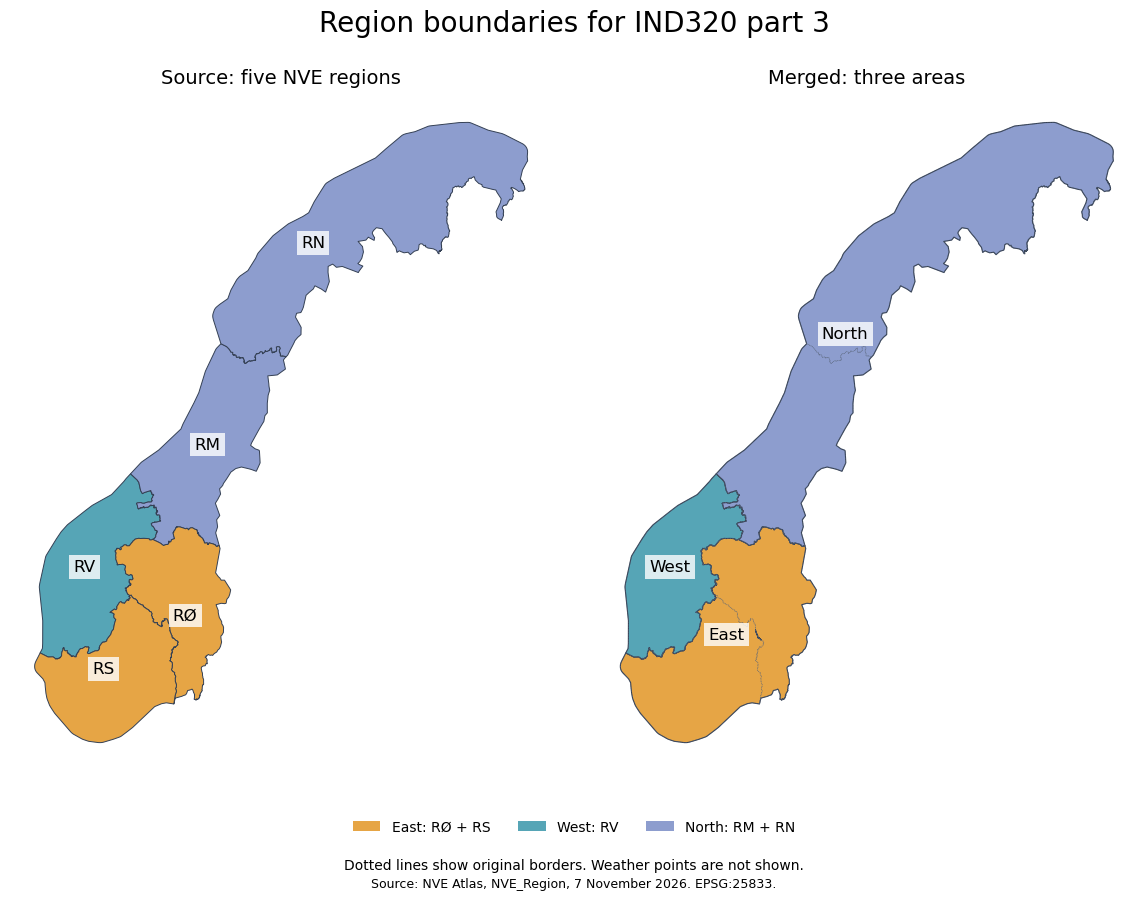

In [4]:
colors = {"East": "#E6A545", "West": "#56A5B6", "North": "#8D9DCE"}
fig, axes = plt.subplots(1, 2, figsize=(12, 9), facecolor="white")
for axis in axes:
    axis.set_facecolor("#F4F6F8")
    axis.set_aspect("equal")
    axis.set_axis_off()

# Left panel: original polygons with their original region codes.
regions.plot(ax=axes[0], color=regions["area"].map(colors),
             edgecolor="#344054", linewidth=0.7)
for _, row in regions.iterrows():
    label_point = row.geometry.representative_point()
    axes[0].text(label_point.x, label_point.y, row["REGION"],
                 ha="center", va="center", fontsize=12,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=3))
axes[0].set_title("Source: five NVE regions", fontsize=14)

# Right panel: merged polygons, with original borders shown as dotted lines.
areas.plot(ax=axes[1], color=areas["area"].map(colors),
           edgecolor="#344054", linewidth=0.8)
regions.boundary.plot(ax=axes[1], color="#596579", linewidth=0.45, linestyle=":")
for _, row in areas.iterrows():
    label_point = row.geometry.representative_point()
    axes[1].text(label_point.x, label_point.y, row["area"],
                 ha="center", va="center", fontsize=12,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=3))
axes[1].set_title("Merged: three areas", fontsize=14)

# Add a shared legend and source information below the maps.
legend_items = [
    Patch(facecolor=colors[row["area"]],
          label=f"{row['area']}: {row['source_regions']}")
    for _, row in areas.iterrows()
]
fig.suptitle("Region boundaries for IND320 part 3", fontsize=20)
fig.legend(handles=legend_items, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 0.05))
fig.text(0.5, 0.025, "Dotted lines show original borders. Weather points are not shown.",
         ha="center", fontsize=10)
fig.text(0.5, 0.005, "Source: NVE Atlas, NVE_Region, 7 November 2026. EPSG:25833.",
         ha="center", fontsize=9)
fig.subplots_adjust(left=0.03, right=0.97, top=0.9, bottom=0.12, wspace=0.08)
plt.show()

### 1.5 Sample 1000 locations in each area

The merged polygons are already available in `areas`, so they can be used directly without saving and reopening an intermediate file.

`sample_points()` draws random locations inside each polygon. Sampling takes place in the projected coordinate system. The fixed seed, `rng=42`, makes the draw reproducible with this environment and input order. Each row of `points_per_region` contains a MultiPoint geometry holding 1000 points.

The three areas produce 3000 points. The checks below confirm the count and that every point lies inside its assigned area.

In [5]:
points_per_area = 1000
points_per_region = areas.geometry.sample_points(size=points_per_area, rng=42)

for index, multipoint in points_per_region.items():
    assert len(multipoint.geoms) == points_per_area
    assert all(areas.geometry.loc[index].contains(point) for point in multipoint.geoms)
    print(f"{areas.loc[index, 'area']}: {len(multipoint.geoms)} points")

East: 1000 points
West: 1000 points
North: 1000 points


### 1.6 Convert the points to longitude and latitude

The weather API needs geographical coordinates rather than projected metre coordinates. `to_crs(epsg=4326)` transforms the points to WGS84. In this coordinate system, `x` is longitude and `y` is latitude.

`coordinates_per_region` stores one list of `(longitude, latitude)` pairs for each area. The loop follows the structure of the lecture example. These lists can be passed to the weather download step. No weather data are downloaded here.

In [6]:
points_wgs84 = points_per_region.to_crs(epsg=4326)
coordinates_per_region = {}

for index, multipoint in points_wgs84.items():
    region_name = areas.loc[index, "area"]
    coordinates_per_region[region_name] = []

    for point in multipoint.geoms:
        latitude = point.y
        longitude = point.x
        coordinates_per_region[region_name].append((longitude, latitude))

    # Display a small sample, rather than printing all 1000 pairs.
    print(f"{region_name}, first three (longitude, latitude) pairs:")
    print(coordinates_per_region[region_name][:3])

assert points_wgs84.crs.to_epsg() == 4326
assert sum(len(points) for points in coordinates_per_region.values()) == 3000

East, first three (longitude, latitude) pairs:
[(6.743984314994531, 57.94538082983031), (9.076473401056122, 59.91419049556114), (8.193685388283756, 60.7342973287599)]
West, first three (longitude, latitude) pairs:
[(6.334796150295968, 60.616448094885584), (4.351736259168014, 60.78186897933524), (7.031672988900803, 63.25804198909316)]
North, first three (longitude, latitude) pairs:
[(24.97181428897678, 69.37720353277649), (23.177668855757382, 69.95939029939014), (18.423432821730692, 68.60154028538581)]
